# Imports

In [2]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [3]:
import os

# Note, this needs to be within your "MyDrive", cannot just be in the shared folder
GOOGLE_DRIVE_PATH_AFTER_MYDRIVE = 'CS5540-Terrain-Classification'
GOOGLE_DRIVE_PATH = os.path.join('drive', 'MyDrive', GOOGLE_DRIVE_PATH_AFTER_MYDRIVE)
print(os.listdir(GOOGLE_DRIVE_PATH))

['Machine Learning Final Project.ipynb', 'data', 'Documentation and Citations.gdoc', 'Proposal Presentation.gslides', 'CS5540 Terrain Classification Project Proposal Report.gdoc']


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.metrics import confusion_matrix, classification_report


# Consolidating the Data

In [5]:
data = pd.DataFrame()
data_path = os.path.join(GOOGLE_DRIVE_PATH, 'data')
for file in os.listdir(data_path):
  file_data = pd.read_csv(os.path.join(data_path, file))
  data = pd.concat([data, file_data])
print(data.head())

   time (ms)   surface   speed   eval_id   ang_vel_x   ang_vel_y   ang_vel_z  \
0          0         0       1         0   -0.003099    0.004498   -0.009037   
1          9         0       1         0    0.007023   -0.007169   -0.017918   
2         15         0       1         0    0.006266   -0.005788   -0.008769   
3         26         0       1         0   -0.003281   -0.012136   -0.009631   
4         36         0       1         0   -0.003529    0.011893    0.001528   

    lin_acc_x   lin_acc_y   lin_acc_z     ori_x     ori_y     ori_z     ori_w  
0    0.105747   -0.273372    9.763157  0.000182  0.013837 -0.940196 -0.340352  
1    0.100696   -0.288692    9.757936  0.000148  0.013811 -0.940163 -0.340444  
2    0.101409   -0.284999    9.744449  0.000122  0.013786 -0.940144 -0.340497  
3    0.061861   -0.258575    9.756163  0.000082  0.013816 -0.940124 -0.340552  
4    0.014422   -0.246492    9.757139  0.000157  0.013807 -0.940123 -0.340556  


In [6]:
# Trim leading whitespaces
replacement_names = {}
for col in data.columns:
  if col[0:1] == ' ':
    replacement_names[col] = col[1:]
  else:
    replacement_names[col] = col
data = data.rename(columns=replacement_names)
data = data.rename(columns={'eval_id':'trial_num'})

In [7]:
num_trials = data['trial_num'].max() + 1
num_surfaces = data['surface'].max() + 1

In [8]:
# For the proposal, we will be working with data for the fastest speed only
proposal_data = data[data.speed == 6][['time (ms)', 'surface', 'speed', 'trial_num', 'lin_acc_x', 'lin_acc_y', 'lin_acc_z', 'ang_vel_x', 'ang_vel_y', 'ang_vel_z', 'ori_x', 'ori_y', 'ori_z', 'ori_w']]

# Create a group_id column to identify groups to be used later
proposal_data['group_id'] = "surface_" + proposal_data['surface'].astype(str) + "_trial_" + proposal_data['trial_num'].astype(str)

proposal_data

,time (ms),surface,speed,trial_num,lin_acc_x,lin_acc_y,lin_acc_z,ang_vel_x,ang_vel_y,ang_vel_z,ori_x,ori_y,ori_z,ori_w,group_id
0,0,0,6,0,-0.066015,-0.233920,9.783689,0.004924,-0.004619,-0.033009,-0.006040,-0.006947,0.858421,0.512863,surface_0_trial_0
1,10,0,6,0,0.130103,-0.179546,9.766088,0.003916,-0.010116,-0.027015,-0.005998,-0.006947,0.858351,0.512981,surface_0_trial_0
2,20,0,6,0,0.240770,-0.196676,9.769207,-0.014010,0.002592,-0.021440,-0.006057,-0.006990,0.858295,0.513074,surface_0_trial_0
3,30,0,6,0,0.151465,-0.231339,9.824692,-0.004389,0.010585,-0.015536,-0.006126,-0.006972,0.858253,0.513143,surface_0_trial_0
4,40,0,6,0,-0.038169,-0.154636,9.783122,-0.002086,0.007412,-0.008099,-0.006176,-0.006952,0.858231,0.513179,surface_0_trial_0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32002,31948,5,6,9,-0.544307,-0.303529,9.815614,0.218167,-0.229403,-0.105625,0.041983,0.000794,0.421735,-0.905746,surface_5_trial_9
32003,31958,5,6,9,-0.062953,1.248773,7.862972,0.062785,-0.217249,-0.150899,0.042148,0.001929,0.422390,-0.905432,surface_5_trial_9
32004,31968,5,6,9,0.832057,0.233796,8.487632,-0.074119,-0.229873,-0.208212,0.042958,0.002843,0.423311,-0.904961,surface_5_trial_9
32005,31978,5,6,9,1.488986,0.441276,8.703191,-0.141301,-0.180745,-0.239528,0.043968,0.003401,0.424370,-0.904414,surface_5_trial_9


In [9]:
# Split the relevant data into smaller dataframes for each surface/trial combination
groups = proposal_data.groupby(['surface', 'trial_num'])
trial_per_surface_dfs = np.empty((num_surfaces, num_trials), dtype=pd.DataFrame)
for name, group in groups:
  # Each group is a dataframe containing only one trial for one surface
  surface = group['surface'].max()
  trial_num = group['trial_num'].max()
  # print("surface: ", surface, " trial_num: ", trial_num)
  trial_per_surface_dfs[surface][trial_num] = group


In [ ]:
# 6 surfaces, 10 trials each
trial_per_surface_dfs.shape

(6, 10)

# Prep data for model inputs

In [10]:
# features (IMU sensor data)
X = proposal_data.drop(columns=['time (ms)', 'surface', 'speed', 'trial_num', 'group_id'])
# target variable (what model is predicting)
y = proposal_data['surface']
# groups in the data that we don't want to separate (trials 0-9 for each terrain type)
groups = proposal_data['group_id']

# 80% train, 20% test split keeping groups together
gss = GroupShuffleSplit(n_splits=1, train_size=0.80, random_state=0)
# get index for the train + test datasets
train_idx, test_idx = next(gss.split(X, y, groups=groups))
# split dataset into training + testing sets
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]

# use sgkf CV to keep groups together with even class distribution
sgkf_cv = StratifiedGroupKFold(n_splits=5)




In [ ]:
X_train.shape

(153644, 10)

# Decision Trees and Random Forest

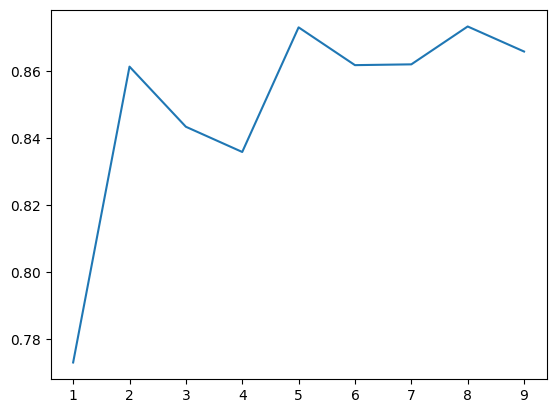

In [ ]:
DTC = DecisionTreeClassifier(random_state=42)
DTC.fit(X_train, y_train)
DTC.score(X_test, y_test)

scores = []
for i in range(1, X_train.shape[1]):
  DTC = DecisionTreeClassifier(random_state=42, max_features=i)
  DTC.fit(X_train, y_train)
  scores.append(DTC.score(X_test, y_test))

plt.plot(range(1, X_train.shape[1]), scores)
plt.show()

start: 10
end: 10
start: 15
end: 15
start: 20
end: 20
start: 25
end: 25
start: 30
end: 30
start: 35
end: 35
start: 40
end: 40
start: 45
end: 45
start: 50
end: 50
start: 55
end: 55
start: 60
end: 60
start: 65
end: 65
start: 70
end: 70
start: 75
end: 75
start: 80
end: 80
start: 85
end: 85
start: 90
end: 90
start: 95
end: 95
start: 100
end: 100
start: 105
end: 105
start: 110
end: 110
start: 115
end: 115
start: 120
end: 120
start: 125
end: 125
start: 130
end: 130
start: 135
end: 135
start: 140
end: 140
start: 145
end: 145
start: 150
end: 150
start: 155
end: 155
start: 160
end: 160
start: 165
end: 165
start: 170
end: 170
start: 175
end: 175
start: 180
end: 180
start: 185
end: 185
start: 190
end: 190
start: 195
end: 195
start: 200
end: 200
start: 205
end: 205
start: 210
end: 210
start: 215
end: 215
start: 220
end: 220
start: 225
end: 225
start: 230
end: 230
start: 235
end: 235
start: 240
end: 240
start: 245
end: 245
start: 250
end: 250
start: 255
end: 255
start: 260
end: 260
start: 265
end: 

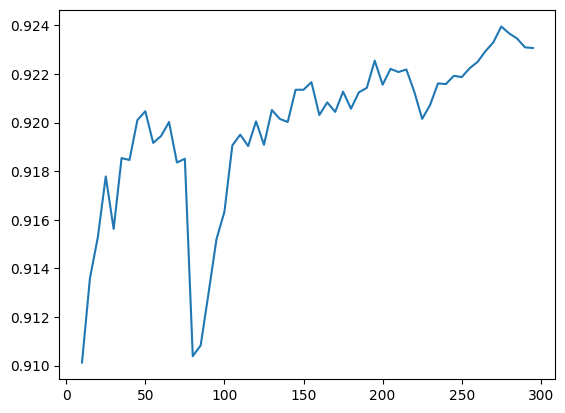

In [ ]:
scores = []
estimators = []
for i in range(10, 300, 5):
  print("start: " + str(i))
  estimators.append(i)
  RFC = RandomForestClassifier(random_state=42, n_estimators=i)
  RFC.fit(X_train, y_train)
  scores.append(RFC.score(X_test, y_test))
  print("end: " + str(i))

plt.plot(estimators, scores)
plt.show()

# Model Evaluation

start: 10
end: 10
start: 15
end: 15
start: 20
end: 20
start: 25
end: 25
start: 30
end: 30
start: 35
end: 35
start: 40
end: 40
start: 45
end: 45
start: 50
end: 50
start: 55
end: 55
start: 60
end: 60
start: 65
end: 65
start: 70
end: 70
start: 75
end: 75
start: 80
end: 80
start: 85
end: 85
start: 90
end: 90
start: 95
end: 95


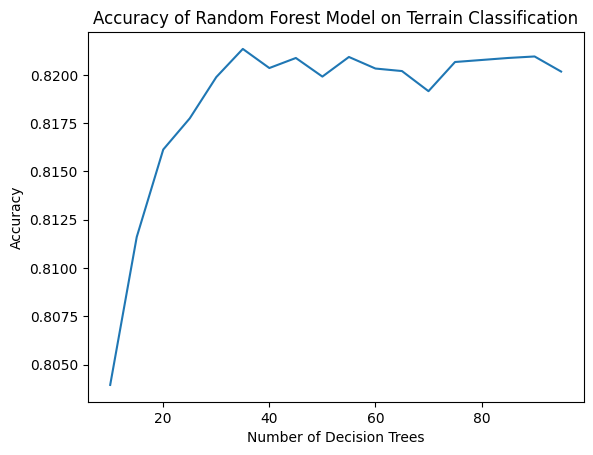

In [11]:
results = []
result_estimators = []
for i in range(10, 100, 5):
  print("start: " + str(i))
  result_estimators.append(i)
  RFC = RandomForestClassifier(random_state=42, n_estimators=i)
  RFC.fit(X_train, y_train)
  results.append(RFC.score(X_test, y_test))
  print("end: " + str(i))

plt.plot(result_estimators, results)
plt.xlabel("Number of Decision Trees")
plt.ylabel("Accuracy")
plt.title("Accuracy of Random Forest Model on Terrain Classification")
plt.show()

In [12]:
#function that you will use to convert matrix to dataframe, useful for visulization.
def conf_matrix_to_df(conf_matrix, target_names):
    return pd.DataFrame(conf_matrix, columns=target_names, index=target_names)

In [16]:
rf = RandomForestClassifier(random_state=42) # use default num_estimators for baseline
rf.fit(X_train, y_train)
score = rf.score(X_test, y_test)

In [ ]:
predictions = rf.predict(X_test)
cr = classification_report(y_test, predictions)
print(cr)

In [15]:
conf_matrix_to_df(confusion_matrix(y_test, predictions), range(6))

,0,1,2,3,4,5
0,6347,0,0,55,0,0
1,2573,520,0,3309,0,0
2,0,0,9601,0,0,0
3,0,0,0,6402,0,0
4,0,0,0,549,2652,0
5,457,0,0,0,0,5944
